## 1. Concept and motivation {#concept-and-motivation}

**Ball Carrier Open Space (BCOS)** is the space a player in possession can navigate without interference from an opponent. Bandara et al. [@bandara2025bcos] define it as the unoccupied area surrounding the ball carrier and investigate its spatial and temporal variation and association with match results.

PRESS extends this concept by assigning an accessibility probability to each candidate destination. Each destination defines a hypothetical straight-line route along which the carrier moves while exposed to interception by opposing players. Reaching the destination and interception are competing terminal events.

The model builds on the probabilistic representation of player movement introduced by Spearman [@spearman2017; @spearman2018beyond]. In the [ball-drive risk model](../../01_ball_drive_risk/01_ball_drive_risk.ipynb), the carrier follows a deterministic trajectory while the movement of defenders is uncertain. BCOS places the carrier and defenders on equal footing by representing both through probabilistic arrival-time distributions. The resulting accessibility surface describes the spatial organization and extent of the carrier's movement opportunities.

The formulation and frame-level example presented here use the final transport-with-killing model. The reported action-selection and residual-risk benchmarks use a preliminary effective-hazard BCOS formulation, which remains available in the package and supplies the BCOS feature to the existing pretrained classifiers. Retraining and held-out evaluation with the final formulation are [planned](../../../roadmap.qmd). Differences between the formulations do not establish a predictive improvement.

## 2. Mathematical formulation {#mathematical-formulation}

The mathematical formulation of BCOS combines probabilistic player movement with transport subject to killing and boundary absorption. The forward equation for diffusion with killing and boundary absorption studied by Holcman, Marchewka and Schuss [@holcman2005] motivates the use of a probability-density equation with an interior sink and an absorbing boundary. In PRESS, the spatial dynamics are described by deterministic transport, killing represents interception of the carrier by a defender, and boundary absorption represents successful arrival at the destination.

We formulate these terminal events as competing risks, providing a common mathematical setting for BCOS, pass risk and ball-drive risk. This formulation also allows the overall interception probability to be decomposed into defender-specific contributions, quantifying the threat posed by individual opponents along a candidate route. The [appendix](../../../appendix/bcos-transport-with-killing.qmd) gives the full derivation, movement kinematics and solution checks.

### Probabilistic player movement

Let $x_{\mathrm{bc}}(0)$ denote the observed position of the carrier. For a candidate destination $z$, the straight-line route is

$$x(\ell;z)=x_{\mathrm{bc}}(0)+\frac{\ell}{L_z}(z-x_{\mathrm{bc}}(0)),\qquad 0\leq\ell\leq L_z,\qquad L_z=\|z-x_{\mathrm{bc}}(0)\|.$$

For each player $j$, the nominal **time to intercept (TTI)** at location $x$ is

$$\tau_j(x)=t_{\mathrm{turn},j}(x)+t_{\mathrm{move},j}(x),$$

where $t_{\mathrm{turn},j}(x)$ is the turning delay required to reorient towards $x$, and $t_{\mathrm{move},j}(x)$ is the travel time under the acceleration-limited movement model of PRESS. Both depend on the player's observed position and velocity. The maximal speed and acceleration of the movement model are set separately for the carrier, who moves with the ball, and for the defenders; their values are given in [Motion parameters](#motion-parameters). For a defender, $\tau_j(x)$ represents the nominal time required to reach a potential interception location; for the carrier, $\tau_{\mathrm{bc}}(x)$ represents the nominal time required to reach that location along the candidate route.
Following Spearman [@spearman2017; @spearman2018beyond], uncertainty is represented by a logistic cumulative distribution,

$$F_j(x,t)=\left[1+\exp\{-\kappa[t-\tau_j(x)]\}\right]^{-1},\qquad \kappa=\frac{\pi}{\sqrt{3}\,s},$$

where $s$ is the standard deviation of arrival-time uncertainty. In the production model, $s$ is the arrival dispersion fitted in the ball-drive risk model on the ten matches. The associated arrival hazard (arrival intensity), conditional on not having reached $x$ by time $t$, is

$$\lambda_j^{\mathrm{arr}}(t\mid x)=\frac{\partial_t F_j(x,t)}{1-F_j(x,t)}=\kappa F_j(x,t).$$

### Carrier transport and boundary condition

Along a route, write $\tau_{\mathrm{bc}}(\ell)=\tau_{\mathrm{bc}}(x(\ell;z))$. The carrier's turning angle is fixed, so $\tau_{\mathrm{bc}}$ is strictly increasing and the transport velocity is $\nu_{\mathrm{bc}}(\ell)=1/\tau_{\mathrm{bc}}'(\ell)$. The reference distribution $F_{\mathrm{bc}}(\ell,t)$ describes the probability that the carrier has reached distance $\ell$ by time $t$. Its spatial density and current are

$$p_0(\ell,t)=-\partial_\ell F_{\mathrm{bc}}(\ell,t),\qquad \nu_{\mathrm{bc}}(\ell)p_0(\ell,t)=\partial_tF_{\mathrm{bc}}(\ell,t).$$

The reference density satisfies $\partial_t p_0+\partial_\ell(\nu_{\mathrm{bc}}p_0)=0$: logistic uncertainty in the carrier's position is propagated along the route.
At the evaluation time $t=0$, the reference distribution assigns mass to the route, to the state preceding entry into the route, and to the destination or beyond. We remove only the last component by conditioning on the carrier not having reached the destination, with $Z_z=1-F_{\mathrm{bc}}(L_z,0)$. The initial interior density is $p_0(\ell,0)/Z_z$.
To preserve Spearman's probabilistic formulation, the remaining mass preceding entry is retained at the origin in a scalar reservoir. Its logistic boundary current supplies the route:

$$M_{\mathrm{res}}(t)=\frac{1-F_{\mathrm{bc}}(0,t)}{Z_z},\qquad j_{\mathrm{in}}(t)=\frac{\partial_tF_{\mathrm{bc}}(0,t)}{Z_z}.$$

In the absence of a turning delay, the boundary logistic is centred at $t=0$, so $F_{\mathrm{bc}}(0,0)=1/2$. A turning delay shifts its centre to $t=\tau_{\mathrm{bc}}(0)$. For sufficiently small $s$, the initial carrier position is concentrated near the observed origin, including the reservoir mass. Retaining the incoming mass preserves the logistic uncertainty during transport and avoids imposing a deterministic initial position or a zero-inflow boundary.

### Transport with interception

Interception occurs when a defender reaches the location occupied by the carrier while the carrier is still in possession. In pitch control, the arrival of each player is evaluated at every point of the ball trajectory, and each point represents an opportunity for interception. BCOS evaluates the arrival of each defender in the same way at every point of the carrier's route, and PRESS specifies the interception intensity of defender $i$ at the carrier's location as its arrival intensity. The total killing intensity is

$$k_z(\ell,t)=\sum_{i\in\mathrm{opp}} k_{z,i}(\ell,t),\qquad k_{z,i}(\ell,t)=\lambda_i^{\mathrm{arr}}(t\mid x(\ell;z)).$$

The density of the carrier still on the route without interception satisfies

$$\boxed{\partial_t p_k+\partial_\ell(\nu_{\mathrm{bc}}p_k)=-k_zp_k.}$$

The initial density is $p_k(\ell,0)=p_0(\ell,0)/Z_z$ and the incoming current is $\lim_{\ell\downarrow0}\nu_{\mathrm{bc}}p_k=j_{\mathrm{in}}(t)$. The reservoir is not subject to killing. The destination is an absorbing outflow boundary.
The form of the solution, obtained using the method of characteristics, is given in the [appendix](../../../appendix/bcos-transport-with-killing.qmd).

### Competing events and accessibility

The destination flux and the interception flux attributable to defender $i$ are

$$j_L(t)=\nu_{\mathrm{bc}}(L_z)p_k(L_z^-,t),\qquad j_i(t)=\int_0^{L_z}k_{z,i}(\ell,t)p_k(\ell,t)\,d\ell.$$

The probability of remaining at risk includes both the reservoir and the surviving mass on the route 

$$S(t)=M_{\mathrm{res}}(t)+\int_0^{L_z}p_k(\ell,t)\,d\ell.$$

The cause-specific hazards are

$$h_L(t)=\frac{j_L(t)}{S(t)},\qquad h_i(t)=\frac{j_i(t)}{S(t)},\qquad h_k(t)=\sum_i h_i(t).$$

The accessibility probability is the cumulative incidence of reaching the destination before interception,

$$\boxed{p_{\mathrm{bc}}(z)=\int_0^\infty S(t)h_L(t)\,dt=\int_0^\infty j_L(t)\,dt.}$$

Similarly, $P_i(z)=\int_0^\infty S(t)h_i(t)\,dt$ is the probability that defender $i$ intercepts the carrier before any other terminal event. Since $p_{\mathrm{bc}}(z)+\sum_iP_i(z)=1$, the competing-risks formulation provides a route-specific attribution of defensive threat in addition to the overall accessibility probability. Without opponents, $p_{\mathrm{bc}}(z)=1$.

### Accessibility surface and BCOS area

Repeating the calculation across destinations produces the accessibility surface $z\mapsto p_{\mathrm{bc}}(z)$. Let $\mathcal D_R$ be the pitch-clipped region within a maximal radius $R$ of the carrier ($R=40$ m in PRESS). Its spatial integral defines the **probability-weighted accessible area**,

$$\boxed{A_{\mathrm{BCOS}}(s_0)=\int_{\mathcal D_R}p_{\mathrm{bc}}(z)\,dz\qquad [\mathrm{m}^2],}$$

where $s_0$ is the observed tracking state. The surface retains the spatial organization of movement opportunities, while the area summarizes their extent.

BCOS is implemented as `PRESS.spatial_features.BCOS`. The probability-weighted accessible area is one of the main features used in the action-selection and residual-risk models of PRESS. The [ball-drive risk model](../../01_ball_drive_risk/01_ball_drive_risk.ipynb) quantifies loss risk over a fixed one-second horizon, with a loss intensity estimated from observed possession losses. BCOS instead evaluates the probability of avoiding interception along routes with destination-dependent durations that can exceed one second, and integrates these probabilities over the surrounding space. It therefore characterizes the carrier's control of the surrounding space and the movement opportunities available beyond the immediate action. This makes BCOS a natural predictor of both the choice between carrying and passing the ball and the residual risk of losing possession following a successful action.

The defender-specific incidences above provide a mathematical decomposition of accessibility; the [example](#example-accessibility-on-a-real-tracking-frame) reports the accessibility surface and area.

## 3. Motion parameters {#motion-parameters}

The carrier and defenders have separate speed limits: $v_{\max,\mathrm{bc}}=6.6$ m/s and $v_{\max,\mathrm{def}}=7$ m/s. Both use linear and turning accelerations of $7$ m/s$^2$. These are common effective movement capabilities, motivated by the literature and checked against the tracking distribution.

| Parameter | Literature rationale | Tracking consistency check |
|---|---|---|
| Defender speed $v_{\max,\mathrm{def}}=7$ m/s | Approximately the 25.1 km/h sprint threshold in Bradley et al. [@bradley2009running], as in ball-drive risk. | Defensive-engagement event frames with speed $>2$ m/s: Q95 = **7.050 m/s**. |
| Carrier speed $v_{\max,\mathrm{bc}}=6.6$ m/s | Benhassen et al. [@benhassen2026dribbling] report an approximately 6% reduction in theoretical maximal velocity during dribbling. Applying this indicative reduction to 7 m/s gives 6.58 m/s, rounded to 6.6. Carling [@carling2010ballrunning] reports mean peak match speeds with the ball of about 6.86 m/s, supporting the broad scale. | In engagement frames where both carrier and defender move above 2 m/s, their Q95 values are **6.778** and **7.174 m/s**, respectively: the carrier value is **5.52% lower**. |
| Defender linear acceleration $a_{\mathrm{def}}=7$ m/s$^2$ | The effective acceleration used by Spearman's movement model [@spearman2018beyond], also used in ball-drive risk. | Defender acceleration peaks per engagement, above 3 m/s$^2$: Q99 = **6.966 m/s$^2$**. |
| Carrier linear acceleration $a_{\mathrm{bc}}=7$ m/s$^2$ | Extending the same arrival-model acceleration scale to the carrier is a modelling assumption, since the cited reduction refers to speed. | Carrier acceleration peaks per engagement give Q99 = **6.682 m/s$^2$** after a threshold of 3 m/s$^2$, and Q98 = **6.953 m/s$^2$** after 4 m/s$^2$. These support a rounded upper scale near 7 m/s$^2$. |
| Turning accelerations $a_{\mathrm{turn,bc}}=a_{\mathrm{turn,def}}=7$ m/s$^2$ | The heading-dependent turning delay follows Pleuler [@pleuler2020handbook]. PRESS sets its scale equal to the corresponding linear-acceleration parameter. | Equality with linear acceleration is a modelling convention; the turning scales are not separately identified by these quantiles. |

The dribbling study reports a theoretical maximal velocity, and the 6% reduction is used as an approximate scale comparison. The carrier cap follows this literature-based reduction and lies below the carrier's tracking Q95. The tracking quantiles are descriptive consistency checks of the chosen limits. The carrier and defender speed comparison uses the same frames, with both players moving; the speed filter removes stationary and walking observations. Acceleration checks use event peaks without a speed filter, retaining acceleration from low speed or rest. The thresholds and quantiles were chosen for exploratory checks.
The [kinematic conventions](../../../docs/kinematic-parameter-conventions.md) give the sampling definitions and sensitivity checks. The model takes observed positions and velocities as inputs. Arrival-time dispersion $s$ is inherited from the fitted ball-drive model, as described above.


## 4. Example: accessibility on a real tracking frame {#example-accessibility-on-a-real-tracking-frame}

The example uses one frame from Brisbane FC–Perth Glory, played on 21 December 2024 (match 1925299) [@skillcorner-opendata]. F. Bérenguer, of Brisbane, has the ball at 06:19 (frame 3800), close to the touchline. The checkpoint was selected because its midfield configuration is easy to read.

The figure shows the accessibility surface $p_{\mathrm{bc}}(z)$ computed from this frame, for destinations within $R=40$ m of the carrier. The colour of each point is the probability that Bérenguer reaches it before any Perth player intercepts him, from 0 (dark) to 1 (light yellow). Blue dots are Brisbane players, red dots Perth players and the white dot is the ball; the short segments are player velocities. The green part of the pitch lies beyond the 40 m region of the calculation.

The accessible space lies mostly to the upper right of the carrier, along the touchline, where no Perth player is close; the highest probabilities are in a compact region next to him. Probability falls quickly towards the centre of the pitch, where several Perth players are positioned. The integral of the surface, the probability-weighted accessible area, is 614.03 m², which is much smaller than the area of the 40 m region because most destinations have a low probability of being reached.



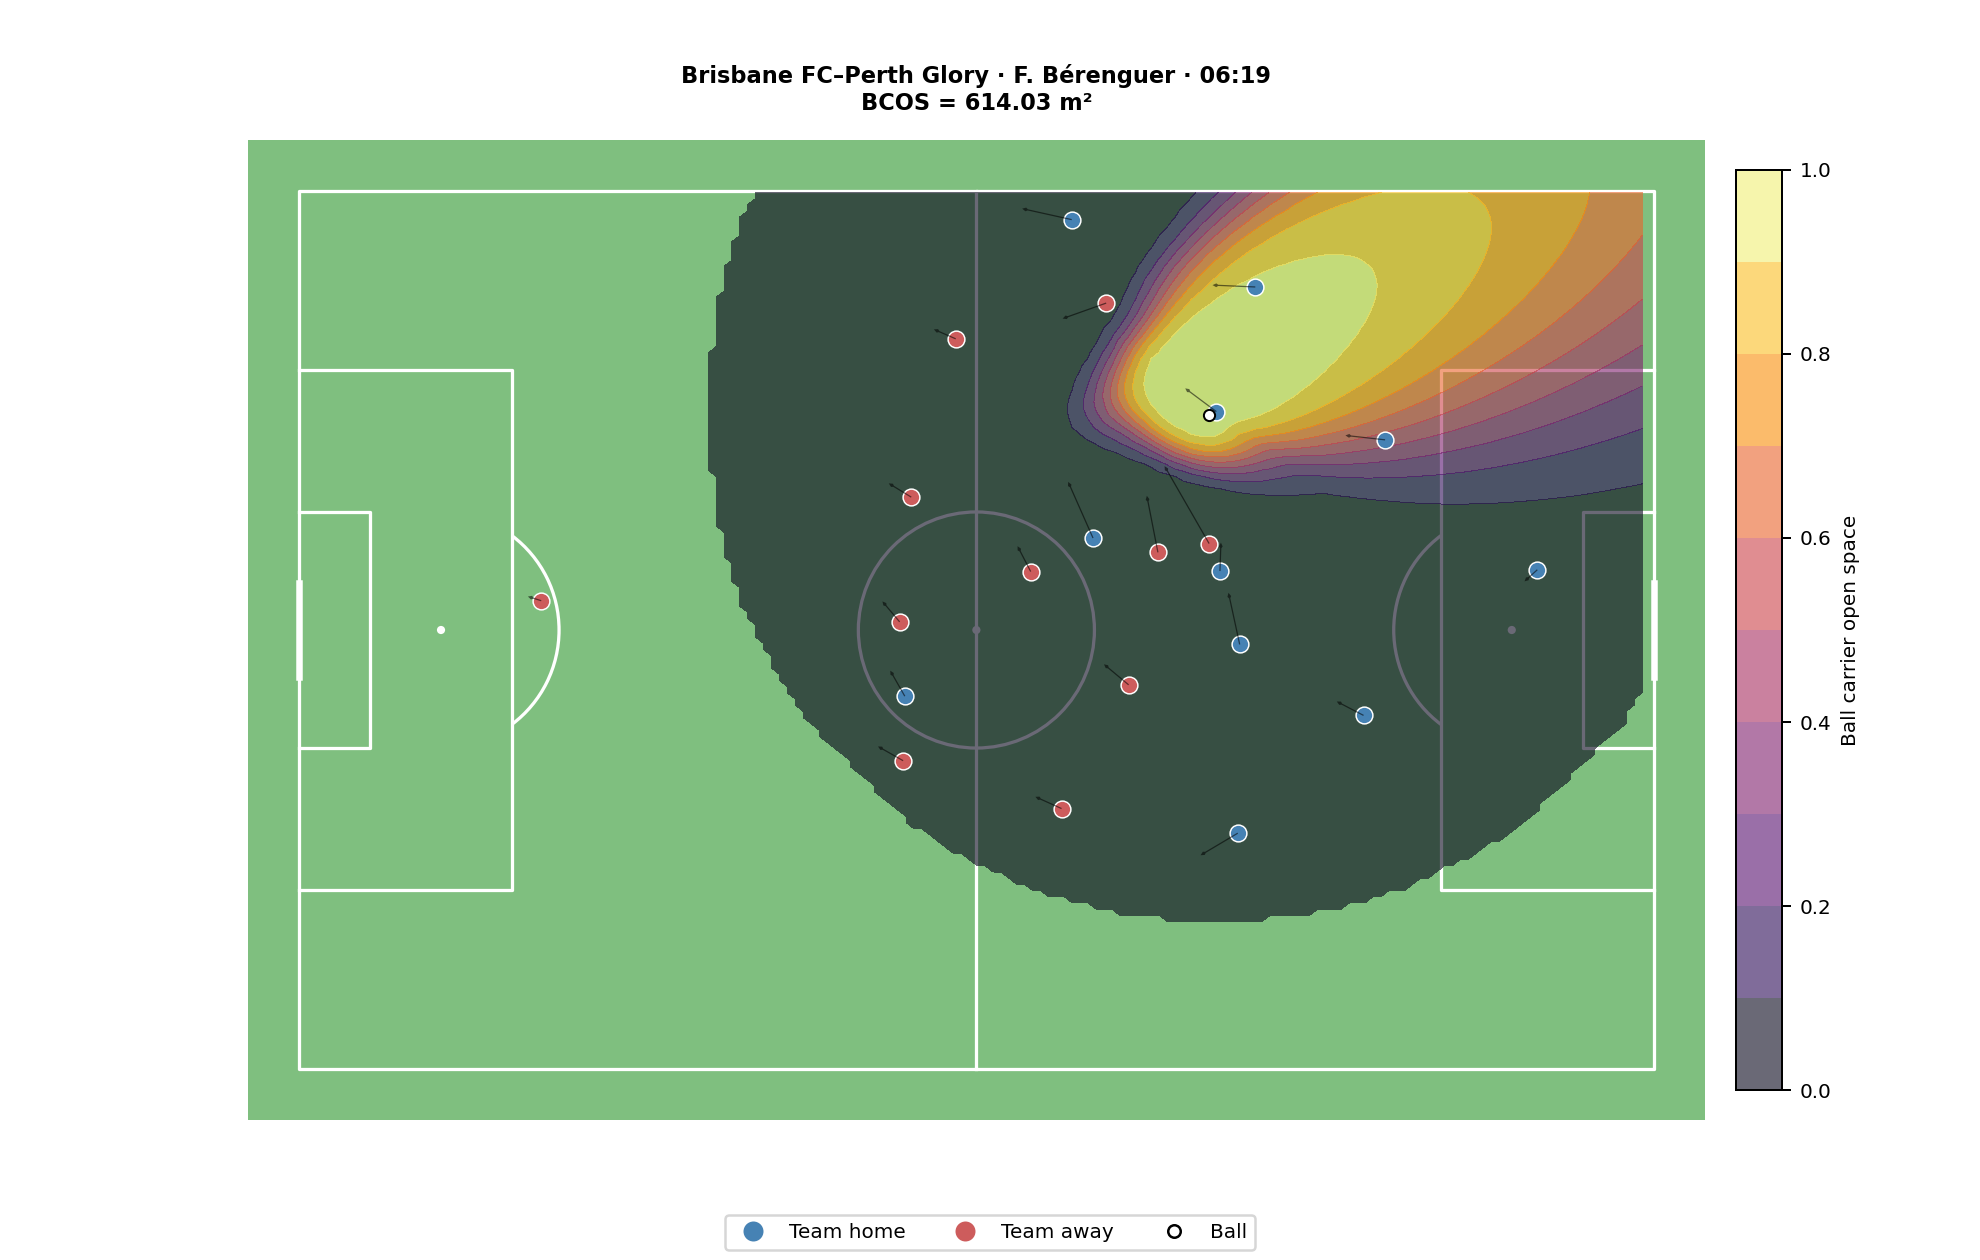

In [5]:
import os
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PRESS import PRESS
from PRESS.visualization import plot_bcos

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "_quarto.yml").is_file())
summary = json.loads((root / "data/examples/bcos/final_example_summary.json").read_text())
match_dir = os.environ.get("PRESS_BCOS_MATCH_DIR")
frame_id = summary["frame_id"]
if match_dir:
    press = PRESS.from_skillcorner(Path(match_dir))
    result = press.compute_bcos(frame_id)  # final transport formulation
    assert np.isclose(result["BCOS area"], summary["bcos_area_m2"], atol=1e-6, rtol=0)
    plot_bcos(press, frame_id, figsize=(11, 7), title_fontsize=12,
              title=f"Brisbane FC–Perth Glory · F. Bérenguer · 06:19\nBCOS = {result['BCOS area']:.2f} m²")
    plt.show()
else:
    from IPython.display import Image, display
    display(Image(filename=str(root / "figures/vignette_10_bcos_transport.png")))

## 5. Spatiotemporal statistics for one match {#spatiotemporal-statistics-for-one-match}

BCOS is also a descriptive statistic of a match. Using the same Brisbane FC–Perth Glory game as above, we report how the BCOS area varies across the pitch, with the position of the carrier, and over the course of the match. The values are the BCOS areas computed at the action-choice checkpoints of the match: the canonical outfield, no-shot decision states, each with its original production value. The sample contains 1,928 checkpoints from 931 individual possessions, 1,238 checkpoints from 592 possessions for Brisbane and 690 from 339 for Perth.

These frozen descriptive summaries use the preliminary effective-hazard formulation, as do the existing classifier benchmarks; they have not been recomputed with the final transport model.

### Spatial distribution by carrier position

The two teams are oriented to attack right, including after halftime. BCOS itself is computed on a one-metre destination grid, and the spatial map uses a 10 × 6 grid for display. For team $a$ and carrier-origin cell $g$, the colour is the mean BCOS area of the checkpoints whose carrier occupies that cell,

$$
\bar A_{a,g}=\frac{1}{n_{a,g}}\sum_{j:\,a_j=a,\,x_{\mathrm{bc},j}\in g}A_{\mathrm{BCOS}}(s_j).
$$

Both teams share one colour scale, and the labels give the number of distinct individual possessions in each cell.

![Mean BCOS by carrier-origin cell, on a 10 × 6 grid. Labels count distinct individual possessions.](../../../figures/bcos_match_spatial.png)

The space available to a carrier depends on its position, because touchlines and goal lines limit it differently in each zone, and carriers in the same third face comparable spatial constraints. Teams are therefore compared third by third. For both teams BCOS decreases from the defensive to the attacking third: 548.31, 365.72 and 81.64 m² for Brisbane, and 277.33, 260.13 and 68.23 m² for Perth. The advantage of Brisbane is largest in the defensive third (270.98 m² more than Perth), is reduced in the central third (105.59 m²) and almost vanishes in the attacking third (13.41 m²). In the defensive third, BCOS correlates with the pressure applied on the build-up from the back, and the difference between the teams is read in this sense: in this match Brisbane's carriers were freer in build-up, while Perth stayed more compact behind. This reading refers to the match analysed.

### Temporal variation

The temporal analysis follows the same thirds across the match and asks how the gaps above evolve between the two halves, separately for each team and carrier-origin third.

![Observed BCOS checkpoints and centred five-minute means, split by carrier-origin third and half.](../../../figures/bcos_match_temporal.png)

In the defensive third, Brisbane's mean rises from 493.02 m² in the first half to 592.92 m² in the second, whereas Perth's falls from 312.02 to 212.03 m². The gap between the teams therefore grows from 181.00 to 380.89 m². In the central third Brisbane stays at a similar level (359.05 → 370.48 m²) while Perth decreases (291.39 → 212.47 m²), and the gap grows from 67.66 to 158.01 m². In the attacking third the means change less for both teams. [Half/third summaries](../../../data/examples/bcos/period_third_summary.csv).

Taken together, the two views describe a match in which Brisbane builds from the back with more space than Perth in both halves, and the advantage increases after the break. The widening gap in the defensive third points to Brisbane building more freely and Perth defending more compactly as the match goes on, especially after the break. This agrees with the course of the match: Perth won 1–0 with a goal in the 69th minute, and Brisbane pushed for an equaliser while Perth held on ([match report](https://brisbaneroar.com.au/news/alm-r9-match-wrap-brisbane-roar-0-1-perth-glory/)). Match statistics add context for this game ([FBref](https://aws.fbref.com/en/matches/f328e2b6/Brisbane-Roar-Perth-Glory-December-21-2024-A-League-Men)): Brisbane had 64% of the possession against 36% for Perth and took more shots (14 against 9), while Perth had more shots on target (6 against 4), tackles won (16 against 10) and interceptions (9 against 1). The larger numbers of individual possessions and checkpoints for Brisbane point in the same direction, since Brisbane has the ball more often.

## 6. Scope and references {#scope-and-references}

BCOS assumes straight hypothetical routes, effective movement limits, logistic arrival uncertainty and an additive interception intensity across defenders, acting on the carrier along the route. Body posture, ball-control skill, adaptive defensive reactions and realized route choice are outside the model, and the match-level summaries refer to the sampled action-choice checkpoints.

Concept and regional temporal analysis: Bandara et al. [@bandara2025bcos]. Arrival/control framework: Spearman [@spearman2017; @spearman2018beyond]. Movement-scale context: Bradley et al. [@bradley2009running] define the speed categories used as operational references (jogging from about 2 m/s, high-speed running from 5.5 m/s, sprinting around 7 m/s); Carling [@carling2010ballrunning] reports speeds when running with the ball, with a mean peak of 24.7 km/h (about 6.86 m/s); Benhassen et al. [@benhassen2026dribbling] report reduced sprint capacity when dribbling. Tracking: [@skillcorner-opendata]. The transport formulation follows the killing-versus-absorption framework of Holcman, Marchewka and Schuss [@holcman2005]; the formulas of the [appendix](../../../appendix/bcos-transport-with-killing.qmd) are derived for the PRESS transport model, and the spatial construction and its numerical implementation are PRESS-specific.

[Spatial support](../../../data/examples/bcos/grid_support.csv) · [spatial statistics](../../../data/examples/bcos/spatial_cells.csv) · [temporal statistics](../../../data/examples/bcos/temporal_thirds.csv).